# 06 - Un réseau de neurones « à la main » avec TensorFlow

Keras cache beaucoup de choses derrière `model.fit()`. Ici on construit et on entraîne un réseau
**sans Keras** (ou presque), avec les briques de bas niveau de TensorFlow :

1. les **fonctions d'activation** et leurs dérivées ;
2. la **différentiation automatique** avec `tf.GradientTape` ;
3. un **perceptron** (un seul neurone) entraîné par descente de gradient écrite à la main ;
4. un **perceptron multicouche** écrit comme un `tf.Module`, entraîné par mini-batch avec Adam ;
5. la comparaison avec le même réseau écrit en Keras.

In [1]:
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from velo_utils import load_splits, plot_history, PALETTE

tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 0. Données

Sans couche `Normalization`, on centre-réduit nous-mêmes les variables, avec la moyenne et l'écart-type
du **train** uniquement. On met aussi 20 % du train de côté pour la validation.

In [2]:
X_train, X_test, y_train, y_test = load_splits()

idx = np.random.default_rng(0).permutation(len(X_train))
n_val = len(idx) // 5
val_idx, tr_idx = idx[:n_val], idx[n_val:]

mean = X_train.iloc[tr_idx].mean().to_numpy()
std = X_train.iloc[tr_idx].std().to_numpy()
std = np.where(std == 0, 1.0, std)  # évite la division par 0

def to_x(X):
    return tf.constant(((X.to_numpy() - mean) / std).astype("float32"))

def to_y(y):
    return tf.constant(y.to_numpy().astype("float32").reshape(-1, 1))

Xtr, Xval, Xte = to_x(X_train.iloc[tr_idx]), to_x(X_train.iloc[val_idx]), to_x(X_test)
ytr, yval, yte = to_y(y_train.iloc[tr_idx]), to_y(y_train.iloc[val_idx]), to_y(y_test)
n_features = Xtr.shape[1]
print("train", Xtr.shape, "| val", Xval.shape, "| test", Xte.shape)

train (468, 33) | val (117, 33) | test (146, 33)


## 1. Fonctions d'activation

Un neurone calcule $a = f(x \cdot w + b)$. La fonction d'activation $f$ apporte la **non-linéarité** ;
sans elle, empiler des couches revient à faire une seule régression linéaire.

Pour l'apprentissage, c'est la **dérivée** de $f$ qui compte : on la calcule ici automatiquement avec `GradientTape`.

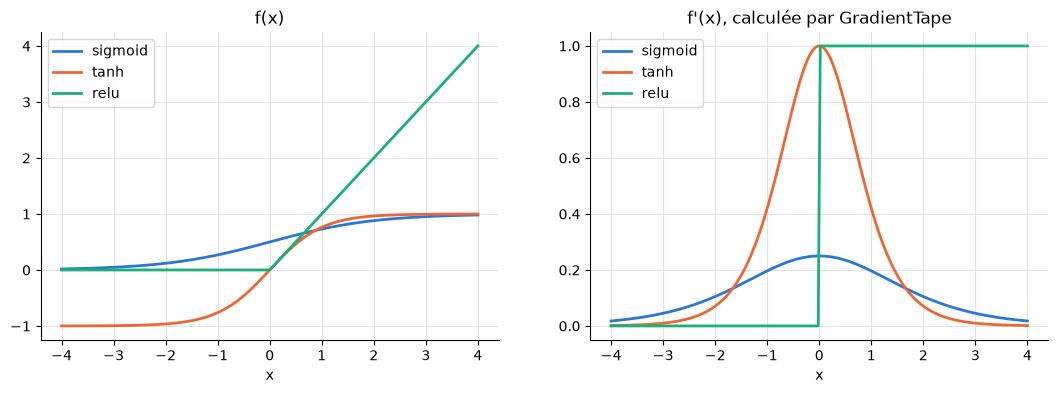

In [3]:
x = tf.linspace(-4.0, 4.0, 200)
activations = {"sigmoid": tf.nn.sigmoid, "tanh": tf.nn.tanh, "relu": tf.nn.relu}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for i, (name, f) in enumerate(activations.items()):
    with tf.GradientTape() as tape:
        tape.watch(x)
        y = f(x)
    dy = tape.gradient(y, x)
    ax1.plot(x, y, color=PALETTE[i], label=name)
    ax2.plot(x, dy, color=PALETTE[i], label=name)
ax1.set(title="f(x)", xlabel="x")
ax2.set(title="f'(x), calculée par GradientTape", xlabel="x")
ax1.legend(); ax2.legend()
plt.show()

La dérivée de `sigmoid` ne dépasse pas 0.25 et celle de `tanh` s'écrase vers 0 aux extrémités :
dans un réseau profond, les gradients se multiplient et peuvent **disparaître**.
`relu` a une dérivée de 1 pour tout $x > 0$, c'est pourquoi c'est l'activation par défaut des couches cachées.

## 2. GradientTape en deux lignes

`tf.GradientTape` enregistre les opérations faites sur des `tf.Variable`, puis calcule les gradients par
**rétropropagation**. Exemple : $L = (3w + 1)^2$ en $w = 2$, donc $\frac{dL}{dw} = 6(3w + 1) = 42$.

In [4]:
w = tf.Variable(2.0)
with tf.GradientTape() as tape:
    L = (3 * w + 1) ** 2
print("dL/dw =", tape.gradient(L, w).numpy())

dL/dw = 42.0


## 3. Le perceptron : un seul neurone, descente de gradient à la main

Le modèle est $\hat{y} = X W + b$ (pas d'activation : c'est une régression linéaire).
À chaque époque, sur **tout** le train (descente de gradient « batch ») :

1. calcul de la prédiction et de la perte MSE ;
2. calcul de $\nabla_W L$ et $\nabla_b L$ ;
3. mise à jour $W \leftarrow W - \eta \nabla_W L$.

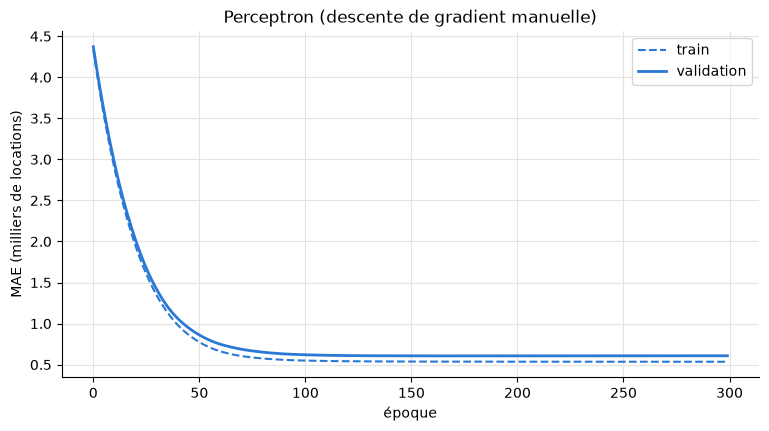

MAE test du perceptron : 0.605 milliers


In [5]:
def mae(y_pred, y_true):
    return float(tf.reduce_mean(tf.abs(y_pred - y_true)))

W = tf.Variable(tf.zeros((n_features, 1)))
b = tf.Variable(0.0)
learning_rate = 0.02

hist_perceptron = {"loss": [], "val_loss": []}
for epoch in range(300):
    with tf.GradientTape() as tape:
        y_pred = Xtr @ W + b
        loss = tf.reduce_mean(tf.square(y_pred - ytr))  # MSE
    dW, db = tape.gradient(loss, [W, b])
    W.assign_sub(learning_rate * dW)
    b.assign_sub(learning_rate * db)

    hist_perceptron["loss"].append(mae(Xtr @ W + b, ytr))
    hist_perceptron["val_loss"].append(mae(Xval @ W + b, yval))

plot_history(SimpleNamespace(history=hist_perceptron), title="Perceptron (descente de gradient manuelle)")
plt.show()
print(f"MAE test du perceptron : {mae(Xte @ W + b, yte):.3f} milliers")

On optimise la MSE mais on affiche la MAE, pour pouvoir comparer avec les autres notebooks.

Les poids appris se lisent directement : chaque variable étant centrée-réduite, un poids positif signifie
« plus cette variable est grande, plus il y a de locations ».

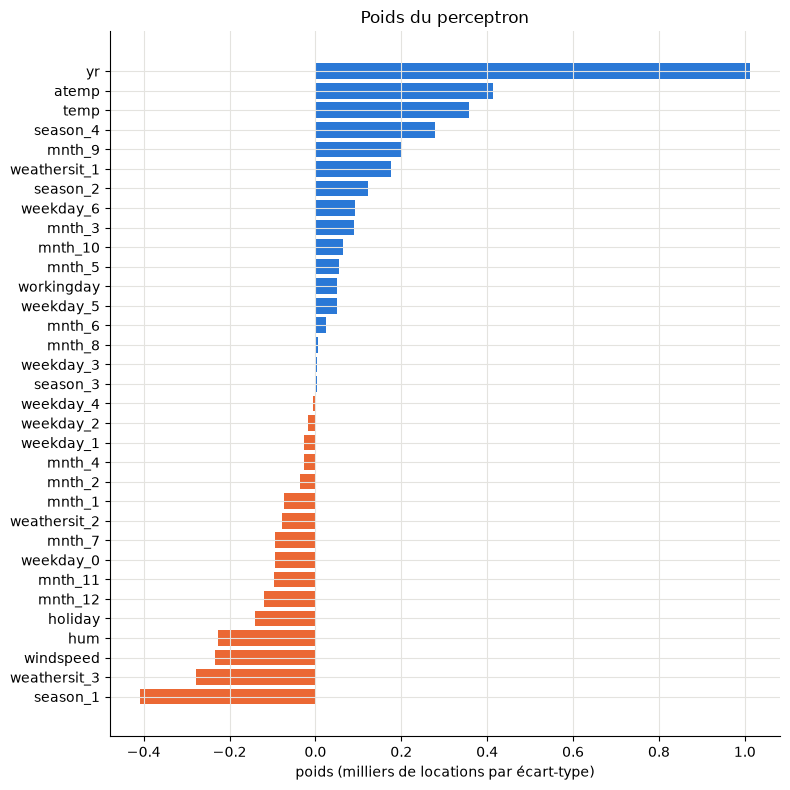

In [6]:
weights = pd.Series(W.numpy().flatten(), index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(weights.index, weights.values, color=[PALETTE[1] if v < 0 else PALETTE[0] for v in weights.values])
ax.set(xlabel="poids (milliers de locations par écart-type)", title="Poids du perceptron")
plt.tight_layout()
plt.show()

## 4. Un perceptron multicouche écrit à la main

Chaque couche est une matrice de poids $W_i$ et un vecteur de biais $b_i$.
La propagation avant enchaîne $h_{i+1} = \text{relu}(h_i W_i + b_i)$, sauf pour la dernière couche qui reste linéaire.
Les poids sont initialisés avec **Glorot** (comme Keras par défaut), les biais à 0.

In [7]:
class MLP(tf.Module):
    def __init__(self, sizes, seed=42):
        super().__init__()
        init = tf.keras.initializers.GlorotUniform(seed=seed)
        self.W = [tf.Variable(init((n_in, n_out)), name=f"W{i}")
                  for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:]))]
        self.b = [tf.Variable(tf.zeros(n_out), name=f"b{i}") for i, n_out in enumerate(sizes[1:])]

    def __call__(self, x):
        for W, b in zip(self.W[:-1], self.b[:-1]):
            x = tf.nn.relu(x @ W + b)
        return x @ self.W[-1] + self.b[-1]


mlp = MLP([n_features, 64, 64, 1])
for v in mlp.trainable_variables:
    print(f"{v.name:6s} {str(v.shape):12s}")
print("Nombre de paramètres :", sum(int(np.prod(v.shape)) for v in mlp.trainable_variables))

W0:0   (33, 64)    
W1:0   (64, 64)    
W2:0   (64, 1)     
b0:0   (64,)       
b1:0   (64,)       
b2:0   (1,)        
Nombre de paramètres : 6401


La boucle d'entraînement fait ce que `model.fit()` fait pour nous :
découpage en mini-batchs mélangés (`tf.data`), propagation avant, perte, gradients, mise à jour par l'optimiseur.
`@tf.function` compile l'étape d'entraînement en graphe TensorFlow, ce qui l'accélère beaucoup.

époque   0  loss=3.282  val_loss=2.340


époque  20  loss=0.341  val_loss=0.563


époque  40  loss=0.236  val_loss=0.524


époque  60  loss=0.174  val_loss=0.549


époque  80  loss=0.161  val_loss=0.571


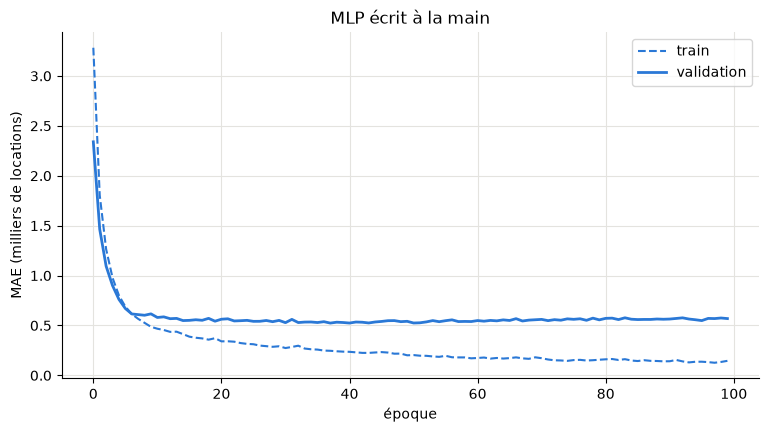

In [8]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean(tf.abs(mlp(x) - y))  # MAE
    grads = tape.gradient(loss, mlp.trainable_variables)
    optimizer.apply_gradients(zip(grads, mlp.trainable_variables))
    return loss

dataset = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(1000, seed=42).batch(32)

hist_mlp = {"loss": [], "val_loss": []}
for epoch in range(100):
    batch_losses = [train_step(x, y) for x, y in dataset]
    hist_mlp["loss"].append(float(tf.reduce_mean(batch_losses)))
    hist_mlp["val_loss"].append(mae(mlp(Xval), yval))
    if epoch % 20 == 0:
        print(f"époque {epoch:3d}  loss={hist_mlp['loss'][-1]:.3f}  val_loss={hist_mlp['val_loss'][-1]:.3f}")

plot_history(SimpleNamespace(history=hist_mlp), title="MLP écrit à la main")
plt.show()

## 5. Le même réseau avec Keras

Nombre de paramètres Keras : 6401


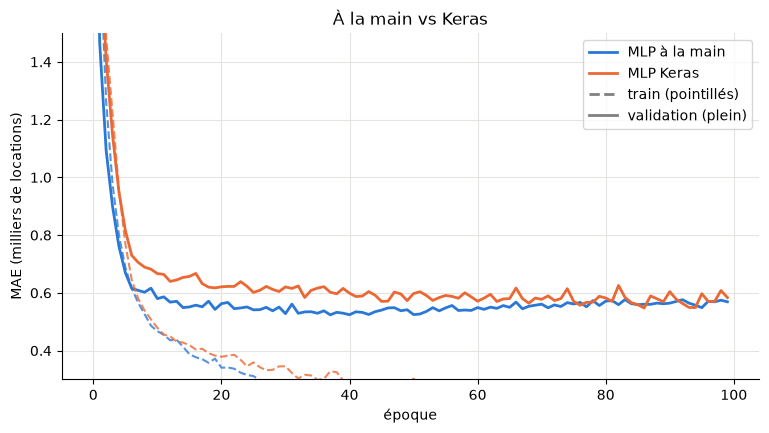

,MAE test (milliers)
perceptron (1 neurone),0.605
MLP à la main,0.552
MLP Keras,0.564


In [9]:
tf.keras.utils.set_random_seed(42)
keras_mlp = tf.keras.Sequential([
    tf.keras.Input(shape=(n_features,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1),
])
keras_mlp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mae")
h_keras = keras_mlp.fit(Xtr, ytr, epochs=100, batch_size=32, validation_data=(Xval, yval), verbose=0)
print("Nombre de paramètres Keras :", keras_mlp.count_params())

plot_history({"MLP à la main": SimpleNamespace(history=hist_mlp), "MLP Keras": h_keras},
             title="À la main vs Keras", ylim=(0.3, 1.5))
plt.show()

pd.DataFrame({
    "MAE test (milliers)": {
        "perceptron (1 neurone)": mae(Xte @ W + b, yte),
        "MLP à la main": mae(mlp(Xte), yte),
        "MLP Keras": mae(keras_mlp(Xte), yte),
    }
}).round(3)

Les deux MLP ont le même nombre de paramètres et des performances équivalentes : `Dense`, `compile` et `fit`
ne font rien d'autre que ce qu'on vient d'écrire.

## À vous de jouer

- Dans le perceptron, testez `learning_rate` = 0.001, 0.1, 0.5 : à partir de quand la descente diverge-t-elle ?
- Remplacez `tf.nn.relu` par `tf.nn.tanh` ou `tf.nn.sigmoid` dans la classe `MLP`.
- Remplacez Adam par une mise à jour manuelle `v.assign_sub(lr * g)` dans `train_step` (SGD pur).
- Ajoutez une pénalité L2 à la perte : `loss += 1e-4 * sum(tf.reduce_sum(W**2) for W in mlp.W)`.